# Phase 2 — Exploratory Data Analysis

This notebook describes the audited MLB hitter data before predictive modeling. The development period is 2015–2025. **The 2026 season is intentionally excluded as a locked holdout.**

We will inspect population sizes, playing-time distributions, Statcast feature coverage, seasonal effects, and the two-part playing-time outcome. We will not train models, tune hyperparameters, or interpret associations causally.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
YEARS = list(range(2015, 2026))
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
RAW = ROOT / 'data' / 'raw'
assert 2026 not in YEARS
print(ROOT)

c:\Users\Jenny\anaconda3\envs\Projects\dodgers_phase1


## Load and standardize development-season files

FanGraphs member exports use `PlayerId`; the audit parser treats this as the FanGraphs identifier. Savant uses MLBAM `player_id`. The Chadwick register provides the crosswalk.

In [2]:
fg_parts, sa_parts = [], []
for year in YEARS:
    fg = pd.read_csv(RAW / f'fangraphs_batting_{year}.csv', low_memory=False)
    fg = fg.rename(columns={'PlayerId': 'fg_id', 'PA': 'pa_fg', 'wRC+': 'wrc_plus'})
    fg['season'] = year
    fg_parts.append(fg[['fg_id', 'season', 'pa_fg', 'wrc_plus', 'wOBA', 'ISO', 'BB%', 'K%']])
    sa = pd.read_csv(RAW / f'savant_custom_{year}.csv', low_memory=False)
    sa = sa.rename(columns={'player_id': 'mlbam_id', 'year': 'season', 'pa': 'pa_savant'})
    sa_parts.append(sa)
fangraphs = pd.concat(fg_parts, ignore_index=True)
savant = pd.concat(sa_parts, ignore_index=True)
print('FanGraphs:', fangraphs.shape, 'Savant:', savant.shape)
display(fangraphs.groupby('season').size().rename('rows').to_frame())

FanGraphs: (15521, 8) Savant: (9173, 12)


,rows
season,
2015,1348
2016,1353
2017,1358
2018,1379
2019,1410
2020,1289
2021,1508
2022,1495
2023,1457


## Population and playing-time exploration

The eligibility threshold is provisional. These summaries describe how much of each season is represented by hitters below and above 150 PA.

,season,hitters,eligible_150,median_pa,max_pa,share_eligible_150
0,2015,1348,389,15.5,713,0.288576
1,2016,1353,394,17.0,744,0.291205
2,2017,1358,391,14.0,725,0.287923
3,2018,1379,392,12.0,745,0.284264
4,2019,1410,411,13.0,747,0.291489
5,2020,1289,203,0.0,267,0.157486
6,2021,1508,411,7.0,724,0.272546
7,2022,1495,417,0.0,724,0.278930
8,2023,1457,404,0.0,753,0.277282
9,2024,1454,410,0.0,735,0.281981


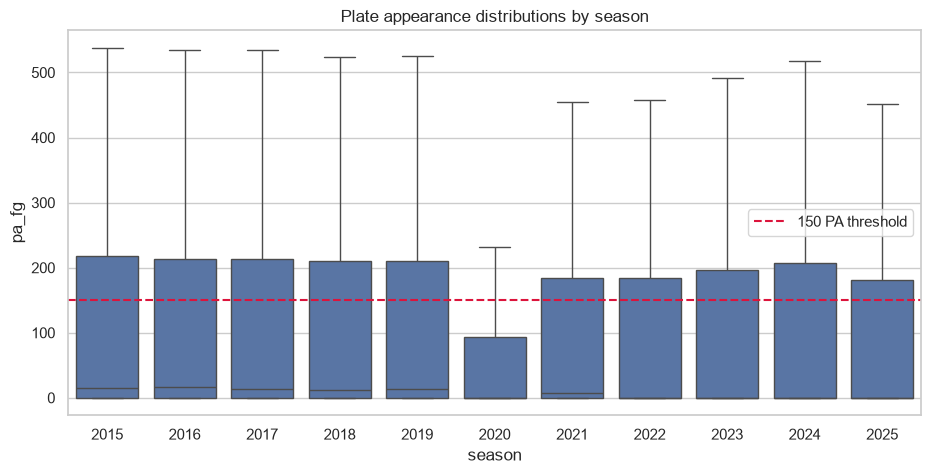

In [3]:
season_summary = fangraphs.groupby('season').agg(
    hitters=('fg_id', 'size'),
    eligible_150=('pa_fg', lambda s: (s >= 150).sum()),
    median_pa=('pa_fg', 'median'),
    max_pa=('pa_fg', 'max'),
).reset_index()
season_summary['share_eligible_150'] = season_summary['eligible_150'] / season_summary['hitters']
display(season_summary)

plt.figure(figsize=(11, 5))
sns.boxplot(data=fangraphs, x='season', y='pa_fg', showfliers=False)
plt.axhline(150, color='crimson', linestyle='--', label='150 PA threshold')
plt.title('Plate appearance distributions by season')
plt.legend()
plt.show()

## Statcast feature coverage

Missingness is reported both across all Savant rows and among the FanGraphs-eligible cohort after joining through Chadwick. Missing values can reflect insufficient batted-ball observations rather than a failed identifier join.

In [4]:
features = ['xwoba', 'woba', 'hard_hit_percent', 'barrel_batted_rate', 'sweet_spot_percent', 'exit_velocity_avg']
missingness = savant.groupby('season')[features].apply(lambda x: x.isna().mean()).round(4)
display(missingness)

eligible = fangraphs.loc[fangraphs['pa_fg'] >= 150, ['fg_id', 'season']].copy()
register_parts = []
for suffix in '0123456789abcdef':
    register_parts.append(pd.read_csv(RAW / f'chadwick_people-{suffix}.csv', usecols=['key_fangraphs', 'key_mlbam']))
register = pd.concat(register_parts, ignore_index=True).rename(columns={'key_fangraphs': 'fg_id', 'key_mlbam': 'mlbam_id'})
register = register.dropna().drop_duplicates()
eligible_joined = eligible.merge(register, on='fg_id', how='left').merge(savant, on=['mlbam_id', 'season'], how='left')
display(eligible_joined.groupby('season')[features].apply(lambda x: x.isna().mean()).round(4))

,xwoba,woba,hard_hit_percent,barrel_batted_rate,sweet_spot_percent,exit_velocity_avg
season,,,,,,
2015,0.0124,0.0062,0.0508,0.0820,0.0508,0.0768
2016,0.0083,0.0052,0.0619,0.0949,0.0619,0.0846
2017,0.0052,0.0031,0.0554,0.0700,0.0543,0.0690
2018,0.0081,0.0061,0.0818,0.0980,0.0798,0.0980
2019,0.0071,0.0040,0.0828,0.1040,0.0808,0.1020
2020,0.0000,0.0000,0.0086,0.0086,0.0086,0.0103
2021,0.0057,0.0057,0.0991,0.1010,0.0991,0.1258
2022,0.0000,0.0000,0.0115,0.0115,0.0115,0.0115
2023,0.0000,0.0000,0.0076,0.0076,0.0076,0.0091


,xwoba,woba,hard_hit_percent,barrel_batted_rate,sweet_spot_percent,exit_velocity_avg
season,,,,,,
2015,0.0,0.0,0.0,0.0,0.0,0.0
2016,0.0,0.0,0.0,0.0,0.0,0.0
2017,0.0,0.0,0.0,0.0,0.0,0.0
2018,0.0,0.0,0.0,0.0,0.0,0.0
2019,0.0,0.0,0.0,0.0,0.0,0.0
2020,0.0,0.0,0.0,0.0,0.0,0.0
2021,0.0,0.0,0.0,0.0,0.0,0.0
2022,0.0,0.0,0.0,0.0,0.0,0.0
2023,0.0,0.0,0.0,0.0,0.0,0.0


## Next-season playing-time outcome

The primary analysis excludes transitions involving 2020. We also exclude 2025→2026 here to protect the holdout. An absent row in an exhaustive FanGraphs season export is treated as zero PA only after the audit has verified the export population.

In [5]:
transitions = [(2015, 2016), (2016, 2017), (2017, 2018), (2018, 2019),
               (2021, 2022), (2022, 2023), (2023, 2024), (2024, 2025)]
fg_by_year = {year: fangraphs.loc[fangraphs.season == year].set_index('fg_id') for year in YEARS}
retention = []
for current, nxt in transitions:
    cohort = fg_by_year[current].loc[lambda x: x.pa_fg >= 150]
    next_pa = fg_by_year[nxt]['pa_fg'].reindex(cohort.index).fillna(0)
    retention.append({'transition': f'{current}->{nxt}', 'eligible': len(cohort),
                     'next_150': int((next_pa >= 150).sum()),
                     'retention_rate': (next_pa >= 150).mean(),
                     'no_next_year_row': int(next_pa.eq(0).sum())})
retention = pd.DataFrame(retention)
display(retention)

,transition,eligible,next_150,retention_rate,no_next_year_row
0,2015->2016,389,309,0.794344,33
1,2016->2017,394,299,0.758883,45
2,2017->2018,391,306,0.782609,36
3,2018->2019,392,302,0.770408,31
4,2021->2022,411,314,0.763990,32
5,2022->2023,417,309,0.741007,37
6,2023->2024,404,315,0.779703,34
7,2024->2025,410,305,0.743902,31


## Threshold sensitivity and next-season performance target

The project plan specifies alternative playing-time thresholds of 100, 150, 200, and 300 PA. These are descriptive checks only; the primary threshold remains 150 PA. The conditional performance target is next-season wRC+ among hitters who reach the selected threshold. The primary target summary excludes transitions involving 2020 and the locked 2026 holdout.

In [6]:
thresholds = [100, 150, 200, 300]
threshold_rows = []
for threshold in thresholds:
    for current, nxt in transitions:
        current_cohort = fg_by_year[current].loc[lambda x: x.pa_fg >= threshold]
        next_pa = fg_by_year[nxt]['pa_fg'].reindex(current_cohort.index).fillna(0)
        threshold_rows.append({
            'threshold': threshold,
            'transition': f'{current}->{nxt}',
            'eligible': len(current_cohort),
            'retained': int((next_pa >= threshold).sum()),
            'retention_rate': (next_pa >= threshold).mean(),
        })
threshold_sensitivity = pd.DataFrame(threshold_rows)
display(threshold_sensitivity.groupby('threshold')[['eligible', 'retained', 'retention_rate']].mean().round(3))

target_rows = []
for current, nxt in transitions:
    current_cohort = fg_by_year[current].loc[lambda x: x.pa_fg >= 150]
    next_year = fg_by_year[nxt].reindex(current_cohort.index)
    retained = next_year.loc[next_year.pa_fg >= 150, 'wrc_plus'].dropna()
    target_rows.append({
        'target_season': nxt,
        'n': len(retained),
        'mean_wrc_plus': retained.mean(),
        'median_wrc_plus': retained.median(),
        'q1_wrc_plus': retained.quantile(0.25),
        'q3_wrc_plus': retained.quantile(0.75),
    })
target_summary = pd.DataFrame(target_rows)
display(target_summary.round(1))

,eligible,retained,retention_rate
threshold,,,
100,451.750,349.000,0.773
150,401.000,307.375,0.767
200,357.000,267.750,0.750
300,277.375,203.125,0.733


,target_season,n,mean_wrc_plus,median_wrc_plus,q1_wrc_plus,q3_wrc_plus
0,2016,309,98.6,100.0,82.8,116.2
1,2017,299,100.0,97.8,84.4,117.0
2,2018,306,99.2,98.6,82.8,116.6
3,2019,302,99.6,99.1,82.3,118.0
4,2022,314,100.1,98.6,82.7,117.7
5,2023,309,99.3,99.8,81.8,116.5
6,2024,315,99.7,97.8,82.6,116.0
7,2025,305,100.8,100.9,83.1,117.9


## Approved EDA decisions

- Include 2020 in descriptive EDA.
- Exclude `2019→2020` and `2020→2021` from the primary forecasting analysis.
- Treat transitions involving 2020 as sensitivity analyses because of the shortened season, unusual playing-time environment, and Statcast tracking-system change.
- Keep 2026 completely excluded as the locked holdout.

These decisions were approved at the Phase 1 review checkpoint. Do not interpret 2020 differences as ordinary season-to-season effects.